# Kâhin deneyi — SegNet basit görüntüleri okuyabiliyor mu?
Ressam yok, eğitim yok. Gerçek segmentasyon haritasını basit görüntülere çevirip SegNet'in ne kadar doğru okuduğuna bakıyoruz.
Karşılaştırma: rekor modelin seg'i ~0.18–0.19. Bu deney yerleşimi mükemmel bildiği için sonuç bir **tavan**.
Pose sonuçları anlamsız (iki kare aynı), sadece **seg**'e bakılır.

## 1. Kurulum

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import torch
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| cihaz:", device)
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name, f"| bellek: {props.total_memory / 2**30:.1f} GB")

ROOT = Path("/content/drive/MyDrive/deneme")
VIDEO_PATH = Path("/content/drive/MyDrive/0.mkv")
MODEL_DIR = ROOT / "models"
TARGET_CACHE = ROOT / "checkpoints" / "hnerv384_targets_evalrgb_v1.pt"
OUT_DIR = ROOT / "b2"                      # b2 modelleri (sadece okunuyor)
OUT_DIR.mkdir(exist_ok=True)

for p in (VIDEO_PATH, MODEL_DIR / "posenet.safetensors", MODEL_DIR / "segnet.safetensors", TARGET_CACHE):
    print("OK " if p.exists() else "YOK", p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu130 | cihaz: cuda
GPU: NVIDIA L4 | bellek: 22.0 GB
OK  /content/drive/MyDrive/0.mkv
OK  /content/drive/MyDrive/deneme/models/posenet.safetensors
OK  /content/drive/MyDrive/deneme/models/segnet.safetensors
OK  /content/drive/MyDrive/deneme/checkpoints/hnerv384_targets_evalrgb_v1.pt


## 2. Hakemler ve hedefler

In [12]:
!uv pip -q install segmentation-models-pytorch timm einops safetensors av

import sys
sys.path.insert(0, str(ROOT))                      # research/ klasörü Drive'da, deneme/ altında
from research.modules import DistortionNet
from research.oracle_pair import seg_preprocess_grad, pose_preprocess_grad

distortion_net = DistortionNet().eval().to(device)
distortion_net.load_state_dicts(MODEL_DIR / "posenet.safetensors", MODEL_DIR / "segnet.safetensors", device)
distortion_net.requires_grad_(False)               # ağırlıkları asla değişmeyecek

n_seg = sum(p.numel() for p in distortion_net.segnet.parameters())
n_pose = sum(p.numel() for p in distortion_net.posenet.parameters())
print(f"SegNet {n_seg / 1e6:.1f}M | PoseNet {n_pose / 1e6:.1f}M parametre (donmuş)")

SegNet 9.5M | PoseNet 13.9M parametre (donmuş)


In [13]:
targets = torch.load(TARGET_CACHE, map_location="cpu", weights_only=True)
seg_targets = targets["seg_class"].to(device, dtype=torch.uint8)    # [600, 384, 512]: piksel başına sınıf
pose_targets = targets["pose"].to(device, dtype=torch.float32)      # [600, 6]: pair başına kamera hareketi
NUM_PAIRS = seg_targets.shape[0]
print("Seg:", tuple(seg_targets.shape), "| Pose:", tuple(pose_targets.shape), "| pair:", NUM_PAIRS)

counts = torch.bincount(seg_targets.flatten().long(), minlength=5)
for c, n in enumerate(counts.tolist()):
    print(f"  class {c}: %{100 * n / counts.sum().item():6.2f}")
print("Pose std (boyut başına):", [round(v, 4) for v in pose_targets.std(0).tolist()])

Seg: (600, 384, 512) | Pose: (600, 6) | pair: 600
  class 0: % 23.23
  class 1: %  0.59
  class 2: % 49.52
  class 3: %  1.24
  class 4: % 25.43
Pose std (boyut başına): [1.2574, 0.0358, 0.0299, 0.0096, 0.0074, 0.0286]


## 3. Ölçüm ve kayıp

In [14]:
import torch.nn.functional as F

def inflate(native):
    """[B, 2, 3, 384, 512] → [B, 2, 3, 874, 1164]. İleri geçişte yuvarlar, geri geçişte gradyanı geçirir."""
    b = native.shape[0]
    up = F.interpolate(native.flatten(0, 1), size=(874, 1164), mode="bicubic", align_corners=False)
    up = up.clamp(0, 255)
    up = up + (up.round() - up).detach()          # STE: ileri = round, geri = özdeşlik
    return up.view(b, 2, 3, 874, 1164)


@torch.no_grad()
def score(render, ids_all, bs=16):
    """render(ids) → [B, 2, 3, 384, 512] (0–255). Resmi ölçümle aynı ayar: FP32, TF32 kapalı."""
    old = (torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
    torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = False
    wrong, pix, pose_sq = 0, 0, 0.0
    for s in range(0, len(ids_all), bs):
        ids = ids_all[s:s + bs]
        full = inflate(render(ids))
        pred = distortion_net.segnet(seg_preprocess_grad(full)).argmax(1)
        pose = distortion_net.posenet(pose_preprocess_grad(full))["pose"][:, :6].float()
        wrong += int((pred != seg_targets[ids].long()).sum())
        pix += pred.numel()
        pose_sq += float((pose - pose_targets[ids]).square().mean(1).sum())
    torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32 = old
    seg, pose_t = 100 * wrong / pix, (10 * pose_sq / len(ids_all)) ** 0.5
    return {"dist": seg + pose_t, "seg": seg, "pose": pose_t}


PILOT = torch.arange(60, device=device)          # ilk 60 pair

In [15]:
import torch.nn as nn

def l7_loss(logits, truth, tau = 0.3,thr =1.0, mult = 4.0):
  correct = logits.gather(1, truth.unsqueeze(1))
  others = logits.clone()
  others.scatter_(1, truth.unsqueeze(1), torch.finfo(others.dtype).min)
  margin = correct - others.amax(1, keepdim = True)
  per_pixel = tau * F.softplus(-margin / tau)

  with torch.no_grad():
    w = 1.0 + mult * (margin < thr).float()
    w = w/w.mean()

  return (per_pixel * w).mean()

## 4. Düz renklerle boyama (boyama kitabı)

In [16]:
def boya(renk, ids):
    """renk: [5, 3] (0–255). Her pikseli kendi sınıfının rengine boyar; iki kare aynı."""
    img = renk[seg_targets[ids].long()].permute(0, 3, 1, 2)          # [B, 3, 384, 512]
    return img.unsqueeze(1).expand(-1, 2, -1, -1, -1)                # [B, 2, 3, 384, 512]

renkler = {
    "gri tonları": torch.tensor([[40] * 3, [90] * 3, [140] * 3, [190] * 3, [240] * 3]),
    "farklı renkler": torch.tensor([[200, 50, 50], [255, 255, 255], [90, 90, 90], [50, 50, 200], [120, 180, 255]]),
}
for ad, r in renkler.items():
    s = score(lambda ids: boya(r.float().to(device), ids), PILOT)
    print(f"{ad:15s} | seg {s['seg']:.4f}")

gri tonları     | seg 1.8422
farklı renkler  | seg 0.9095


## 5. SegNet'in en sevdiği renkleri öğren (15 sayı, ~1 dk)

In [17]:
logit = nn.Parameter(torch.zeros(5, 3, device=device))
opt = torch.optim.Adam([logit], lr=0.05)
for adim in range(500):
    ids = PILOT[torch.randperm(len(PILOT), device=device)[:8]]
    renk = torch.sigmoid(logit) * 255
    logits = distortion_net.segnet(seg_preprocess_grad(inflate(boya(renk, ids))))
    loss = l7_loss(logits, seg_targets[ids].long())
    opt.zero_grad(); loss.backward(); opt.step()
    if (adim + 1) % 100 == 0:
        s = score(lambda i: boya(torch.sigmoid(logit) * 255, i), PILOT)
        print(f"adım {adim + 1} | seg {s['seg']:.4f}")
print("öğrenilen renkler:", (torch.sigmoid(logit) * 255).round().int().tolist())

adım 100 | seg 1.0533
adım 200 | seg 0.9247
adım 300 | seg 0.8480
adım 400 | seg 0.7568
adım 500 | seg 0.7006
öğrenilen renkler: [[133, 148, 139], [137, 122, 128], [81, 78, 162], [146, 106, 80], [95, 152, 103]]


## 6. Renk yerine 16×16 desen (~2 dk)

In [18]:
T = 16
tile = nn.Parameter(torch.zeros(5, 3, T, T, device=device))
opt = torch.optim.Adam([tile], lr=0.05)

def desenle(ids):
    tex = (torch.sigmoid(tile) * 255).repeat(1, 1, 384 // T, 512 // T)          # [5, 3, 384, 512]
    oh = F.one_hot(seg_targets[ids].long(), 5).permute(0, 3, 1, 2).float()     # [B, 5, 384, 512]
    img = (oh.unsqueeze(2) * tex.unsqueeze(0)).sum(1)                           # [B, 3, 384, 512]
    return img.unsqueeze(1).expand(-1, 2, -1, -1, -1)

for adim in range(1000):
    ids = PILOT[torch.randperm(len(PILOT), device=device)[:8]]
    loss = l7_loss(distortion_net.segnet(seg_preprocess_grad(inflate(desenle(ids)))), seg_targets[ids].long())
    opt.zero_grad(); loss.backward(); opt.step()
    if (adim + 1) % 100 == 0:
        print(f"adım {adim + 1} | seg {score(lambda i: desenle(i), PILOT)['seg']:.4f}")

adım 100 | seg 4.4375
adım 200 | seg 2.7455
adım 300 | seg 1.8944
adım 400 | seg 1.3758
adım 500 | seg 1.1517
adım 600 | seg 1.0235
adım 700 | seg 0.9382
adım 800 | seg 0.8690
adım 900 | seg 0.8124
adım 1000 | seg 0.7657


## 7. Ressam şu an ne çiziyor? (rekor model)

In [19]:
import math
import torch.nn as nn
GRID_LEVELS = {64:2, 32:2, 16:2}
WIDTHS = [16, 16, 16, 16, 12, 12, 8]

class GridDecoder(nn.Module):
  def __init__(self, n_pairs, levels = GRID_LEVELS, widths = WIDTHS):
    super().__init__()
    self.grids = nn.ParameterDict({str(d): nn.Parameter(torch.zeros(n_pairs, c, 384 // d, 512 // d))
                                  for d, c in levels.items()})

    self.inject = nn.ModuleDict({str(d): nn.Conv2d(c, widths[int(math.log2(64 // d))], 1)
                                     for d, c in levels.items()})
    self.ups = nn.ModuleList(nn.Conv2d(widths[i], 4 * widths[i + 1], 3, padding=1) for i in range(6))
    self.skips = nn.ModuleList(nn.Conv2d(widths[i], widths[i + 1], 1) for i in range(6))
    self.head = nn.Conv2d(widths[-1], 6, 3, padding=1)
  def forward(self, ids, grids = None):
    g = grids if grids is not None else {k: v[ids] for k, v in self.grids.items()}
    x = self.inject["64"](g["64"])
    for i in range(6):
      up = F.pixel_shuffle(self.ups[i](x), 2)
      skip = F.interpolate(self.skips[i](x), scale_factor = 2, mode = "bilinear", align_corners = False)
      x = F.gelu(up + skip)
      d = str(64//2 ** (i+1))
      if d in self.inject:
        x = x + self.inject[d](g[d])
    return (torch.sigmoid(self.head(x)) * 255).view(len(ids), 2, 3, 384, 512)

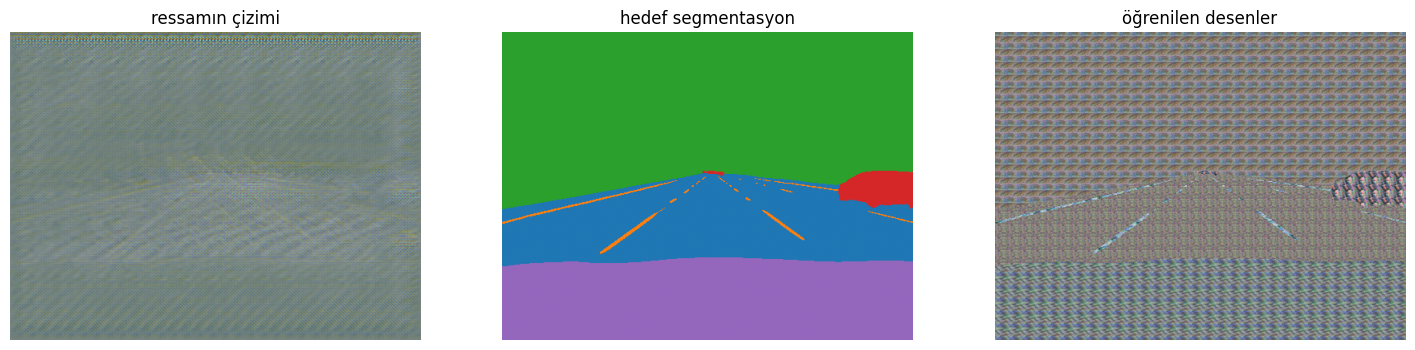

In [20]:
import matplotlib.pyplot as plt
ck = torch.load(OUT_DIR / "pilot_rate_l100_netft900.pt", map_location=device)
md = GridDecoder(NUM_PAIRS).to(device); md.load_state_dict(ck["model"]); md.eval()
with torch.no_grad():
    cizim = md(PILOT[:1])[0, 1].permute(1, 2, 0).cpu().numpy() / 255
    desen = desenle(PILOT[:1])[0, 1].permute(1, 2, 0).cpu().numpy() / 255
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(cizim); ax[0].set_title("ressamın çizimi")
ax[1].imshow(seg_targets[0].cpu(), cmap="tab10", vmin=0, vmax=9); ax[1].set_title("hedef segmentasyon")
ax[2].imshow(desen); ax[2].set_title("öğrenilen desenler")
for a in ax: a.axis("off")
plt.show()

## Okuma
| Sonuç (5. ya da 6. hücre) | Anlamı |
|---|---|
| seg < 0.10 | Boyama kitabı çok güçlü → ressamı "yerleşim + kalıp" olarak kurmak büyük kazanç getirebilir |
| 0.10–0.20 | Umut verici, tek başına yetmez |
| > 0.5 | SegNet gerçek doku/bağlam istiyor → yön zayıf |